In [4]:
import pandas as pd 
import numpy as np

%pip install matplotlib seaborn
import matplotlib.pyplot as plt
import seaborn as sns


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [5]:
df=pd.read_csv(r"/Users/drashtidarji/Documents/my projects/Housing Prices Prediction/cleaned_housing_data.csv")

In [6]:
print("Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
display(df.head())

Dataset Shape: (1460, 81)
Missing Values: 867


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NoAlley,Reg,Lvl,AllPub,...,0,NoPool,NoFence,NoFeature,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NoAlley,Reg,Lvl,AllPub,...,0,NoPool,NoFence,NoFeature,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NoAlley,IR1,Lvl,AllPub,...,0,NoPool,NoFence,NoFeature,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NoAlley,IR1,Lvl,AllPub,...,0,NoPool,NoFence,NoFeature,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NoAlley,IR1,Lvl,AllPub,...,0,NoPool,NoFence,NoFeature,0,12,2008,WD,Normal,250000


In [7]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

display(missing)

MasVnrType    867
dtype: int64

In [8]:
df = pd.read_csv("cleaned_housing_data.csv", keep_default_na=False)

In [9]:
print("Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())

Dataset Shape: (1460, 81)
Missing Values: 0


In [10]:
# create 2 variables 

# X = House ki features (80 columns)
# y = SalePrice (1 column)

In [11]:
X = df.drop("SalePrice", axis=1)
y = df["SalePrice"]

In [12]:
print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (1460, 80)
y Shape: (1460,)


In [13]:
# Train-Test Split (80:20)

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [14]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1168, 80)
X_test: (292, 80)
y_train: (1168,)
y_test: (292,)


In [15]:
# combine Training Data 

train_data = X_train.copy()

train_data["SalePrice"] = y_train

In [16]:
print(train_data.shape)
display(train_data.head())

(1168, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
254,255,20,RL,70.0,8400,Pave,NoAlley,Reg,Lvl,AllPub,...,0,NoPool,NoFence,NoFeature,0,6,2010,WD,Normal,145000
1066,1067,60,RL,59.0,7837,Pave,NoAlley,IR1,Lvl,AllPub,...,0,NoPool,NoFence,NoFeature,0,5,2009,WD,Normal,178000
638,639,30,RL,67.0,8777,Pave,NoAlley,Reg,Lvl,AllPub,...,0,NoPool,MnPrv,NoFeature,0,5,2008,WD,Normal,85000
799,800,50,RL,60.0,7200,Pave,NoAlley,Reg,Lvl,AllPub,...,0,NoPool,MnPrv,NoFeature,0,6,2007,WD,Normal,175000
380,381,50,RL,50.0,5000,Pave,Pave,Reg,Lvl,AllPub,...,0,NoPool,NoFence,NoFeature,0,5,2010,WD,Normal,127000


In [17]:
print("Training Data Shape:", train_data.shape)

print("Missing Values:", train_data.isnull().sum().sum())

print("SalePrice Column Present:", "SalePrice" in train_data.columns)

Training Data Shape: (1168, 81)
Missing Values: 0
SalePrice Column Present: True


In [18]:
# Numerical vs Categorical Columns

In [19]:
numerical_cols = train_data.select_dtypes(include=["int64", "float64"]).columns

categorical_cols = train_data.select_dtypes(include=["object", "str", "string"]).columns

print("Numerical Columns:", len(numerical_cols))
print("Categorical Columns:", len(categorical_cols))

Numerical Columns: 38
Categorical Columns: 43


In [20]:
# MSSubClass mportant check

In [21]:
print("MSSubClass Data Type:", train_data["MSSubClass"].dtype)

MSSubClass Data Type: int64


In [22]:
train_data["MSSubClass"] = train_data["MSSubClass"].astype(str)

In [23]:
print(train_data["MSSubClass"].dtype)

str


In [24]:
numerical_cols = train_data.select_dtypes(include=["int64", "float64"]).columns

categorical_cols = train_data.select_dtypes(include=["object", "str", "string"]).columns

print("Numerical Columns:", len(numerical_cols))
print("Categorical Columns:", len(categorical_cols))
print("Total Columns:", len(numerical_cols) + len(categorical_cols))

Numerical Columns: 37
Categorical Columns: 44
Total Columns: 81


In [25]:
# identify a Numerical Columns 

print(numerical_cols.tolist())

['Id', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']


In [26]:
print(categorical_cols.tolist())

['MSSubClass', 'MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


In [27]:
# check Neighborhood distribution 

train_data["Neighborhood"].value_counts()

Neighborhood
NAmes      181
CollgCr    115
OldTown     91
Edwards     87
Somerst     69
NWAmes      66
Gilbert     65
NridgHt     61
Sawyer      58
BrkSide     45
Crawfor     44
SawyerW     44
Mitchel     40
NoRidge     33
Timber      28
IDOTRR      26
SWISU       21
StoneBr     20
ClearCr     19
Blmngtn     15
BrDale      13
MeadowV     10
Veenker      9
NPkVill      7
Blueste      1
Name: count, dtype: int64

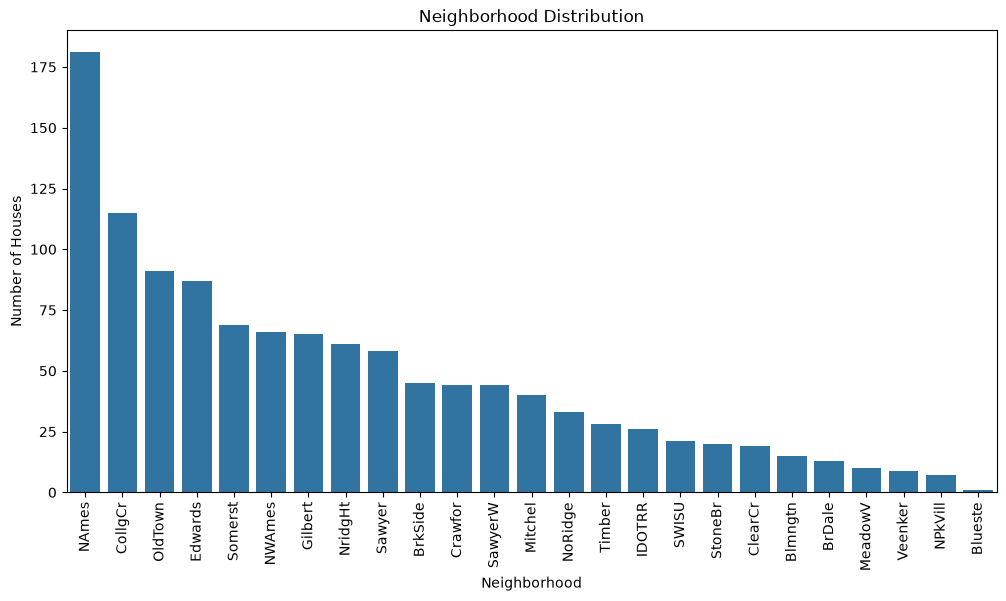

In [28]:
# Numerical Data Distribution

plt.figure(figsize=(12, 6))

sns.countplot(data=train_data,x="Neighborhood",order=train_data["Neighborhood"].value_counts().index)

plt.xticks(rotation=90)
plt.title("Neighborhood Distribution")
plt.xlabel("Neighborhood")
plt.ylabel("Number of Houses")
plt.show()

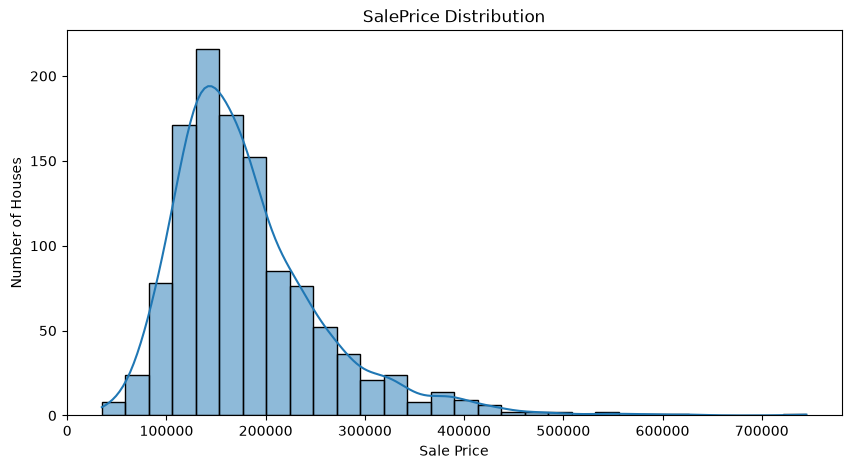

In [29]:
# SalePrice Histogram

plt.figure(figsize=(10, 5))

sns.histplot(data=train_data, x="SalePrice", bins=30, kde=True)

plt.title("SalePrice Distribution")
plt.xlabel("Sale Price")
plt.ylabel("Number of Houses")

plt.show()

In [30]:
# Manual Synthetic Data Generation

In [31]:
# Bootstrap Sampling

synthetic_data = train_data.sample(n=500,replace=True,random_state=42)

In [32]:
print("Synthetic Data Shape:", synthetic_data.shape)
display(synthetic_data.head())

Synthetic Data Shape: (500, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
1267,1268,20,RL,89.0,13214,Pave,NoAlley,IR1,HLS,AllPub,...,0,NoPool,NoFence,NoFeature,0,5,2010,WD,Normal,378500
992,993,60,RL,80.0,9760,Pave,NoAlley,Reg,Lvl,AllPub,...,0,NoPool,MnWw,NoFeature,0,7,2007,WD,Normal,187000
957,958,20,RL,70.0,7420,Pave,NoAlley,Reg,Lvl,AllPub,...,0,NoPool,NoFence,NoFeature,0,4,2007,WD,Normal,132000
401,402,20,RL,65.0,8767,Pave,NoAlley,IR1,Lvl,AllPub,...,0,NoPool,NoFence,NoFeature,0,7,2006,New,Partial,164990
725,726,20,RL,60.0,6960,Pave,NoAlley,Reg,Lvl,AllPub,...,0,NoPool,NoFence,Shed,500,11,2009,WD,Normal,120500


In [33]:
# uplicate Rows Check

print("Total Rows:", len(synthetic_data))

print("Duplicate Rows:", synthetic_data.duplicated().sum())

Total Rows: 500
Duplicate Rows: 93


In [34]:
# Original aur Bootstrap Data ka comparison

print("Original Training Rows:", len(train_data))
print("Bootstrap Sample Rows:", len(synthetic_data))

print("Original Unique Houses:", train_data["Id"].nunique())
print("Bootstrap Unique Houses:", synthetic_data["Id"].nunique())

Original Training Rows: 1168
Bootstrap Sample Rows: 500
Original Unique Houses: 1168
Bootstrap Unique Houses: 407


In [35]:
# identify Numerical Features 

numerical_cols = synthetic_data.select_dtypes(include=["int64", "float64"]).columns.tolist()

print("Total Numerical Columns:", len(numerical_cols))
print(numerical_cols)

Total Numerical Columns: 37
['Id', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']


In [36]:
numerical_features = [
    col for col in numerical_cols
    if col not in ["Id", "SalePrice"]
]

print("Numerical Features:", len(numerical_features))
print(numerical_features)

Numerical Features: 35
['LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold']


In [37]:
# Continuous aur Discrete Features

In [38]:
# Continuous Features

continuous_cols = [
    "LotFrontage",
    "LotArea",
    "MasVnrArea",
    "BsmtFinSF1",
    "BsmtFinSF2",
    "BsmtUnfSF",
    "TotalBsmtSF",
    "1stFlrSF",
    "2ndFlrSF",
    "LowQualFinSF",
    "GrLivArea",
    "GarageArea",
    "WoodDeckSF",
    "OpenPorchSF",
    "EnclosedPorch",
    "3SsnPorch",
    "ScreenPorch",
    "PoolArea",
    "MiscVal"
]

print("Continuous Features:", len(continuous_cols))

Continuous Features: 19


In [39]:
# Discrete Features

discrete_cols = [
    "OverallQual",
    "OverallCond",
    "BsmtFullBath",
    "BsmtHalfBath",
    "FullBath",
    "HalfBath",
    "BedroomAbvGr",
    "KitchenAbvGr",
    "TotRmsAbvGrd",
    "Fireplaces",
    "GarageCars"
]

print("Discrete / Ordinal Features:", len(discrete_cols))
print(discrete_cols)

Discrete / Ordinal Features: 11
['OverallQual', 'OverallCond', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageCars']


In [40]:
# Date / Time Features

In [41]:
date_cols = [
    "YearBuilt",
    "YearRemodAdd",
    "GarageYrBlt",
    "MoSold",
    "YrSold"
]

print("Date / Time Features:", len(date_cols))
print(date_cols)

Date / Time Features: 5
['YearBuilt', 'YearRemodAdd', 'GarageYrBlt', 'MoSold', 'YrSold']


In [42]:
# Verify Feature Classification 

In [43]:
all_classified_cols = (continuous_cols + discrete_cols + date_cols)

print("Total Classified Columns:", len(all_classified_cols))

print("Unique Classified Columns:", len(set(all_classified_cols)))

print("Missing Columns:",set(numerical_features) - set(all_classified_cols))

print("Extra Columns:",set(all_classified_cols) - set(numerical_features))

Total Classified Columns: 35
Unique Classified Columns: 35
Missing Columns: set()
Extra Columns: set()


In [44]:
# Standard Deviation

continuous_stats = synthetic_data[continuous_cols].describe().T

display(
    continuous_stats[["mean", "std", "min", "max"]]
)

,mean,std,min,max
LotFrontage,70.911,21.989945,21.0,313.0
LotArea,10904.482,10004.977037,1477.0,164660.0
MasVnrArea,96.110,157.273481,0.0,1047.0
BsmtFinSF1,441.122,434.540597,0.0,1810.0
BsmtFinSF2,45.350,162.014100,0.0,1120.0
BsmtUnfSF,587.566,454.142860,0.0,2121.0
TotalBsmtSF,1074.038,436.843346,0.0,3200.0
1stFlrSF,1185.028,391.687945,372.0,3228.0
2ndFlrSF,342.810,432.141447,0.0,1818.0
LowQualFinSF,6.646,48.857536,0.0,513.0


In [45]:
# Analysis Zero Values 

zero_counts = (synthetic_data[continuous_cols] == 0).sum()

zero_percentage = (
    (zero_counts / len(synthetic_data)) * 100
).round(2)

zero_analysis = pd.DataFrame({
    "Zero Count": zero_counts,
    "Zero Percentage": zero_percentage
})

display(zero_analysis.sort_values(
    by="Zero Percentage",
    ascending=False
))

,Zero Count,Zero Percentage
PoolArea,499,99.8
3SsnPorch,491,98.2
LowQualFinSF,488,97.6
MiscVal,480,96.0
ScreenPorch,457,91.4
BsmtFinSF2,446,89.2
EnclosedPorch,434,86.8
MasVnrArea,293,58.6
2ndFlrSF,281,56.2
WoodDeckSF,249,49.8


In [46]:
# Basement Area relationship check

basement_check = (
    synthetic_data["BsmtFinSF1"]
    + synthetic_data["BsmtFinSF2"]
    + synthetic_data["BsmtUnfSF"]
)

difference = (
    synthetic_data["TotalBsmtSF"] - basement_check
)

print("Matching Rows:", (difference == 0).sum())

print("Mismatching Rows:", (difference != 0).sum())

Matching Rows: 500
Mismatching Rows: 0


In [47]:
# GrLivArea relationship check

grliv_check = (
    synthetic_data["1stFlrSF"]
    + synthetic_data["2ndFlrSF"]
    + synthetic_data["LowQualFinSF"]
)

difference = synthetic_data["GrLivArea"] - grliv_check

print("Matching Rows:", (difference == 0).sum())
print("Mismatching Rows:", (difference != 0).sum())

Matching Rows: 500
Mismatching Rows: 0


In [48]:
# Garage Relationship Check

garage_check = synthetic_data[
    ["GarageCars", "GarageArea"]
]

display(garage_check.head(10))

print(
    "GarageCars = 0 but GarageArea > 0:",
    (
        (synthetic_data["GarageCars"] == 0) &
        (synthetic_data["GarageArea"] > 0)
    ).sum()
)

print(
    "GarageCars > 0 but GarageArea = 0:",
    (
        (synthetic_data["GarageCars"] > 0) &
        (synthetic_data["GarageArea"] == 0)
    ).sum()
)

,GarageCars,GarageArea
1267,3,746
992,2,440
957,2,576
401,2,400
725,2,660
199,3,856
1270,2,586
622,2,484
100,2,480
646,2,420


GarageCars = 0 but GarageArea > 0: 0
GarageCars > 0 but GarageArea = 0: 0


In [49]:
# comparison of Original aur Bootstrap Sample 

print("Original Training SalePrice:")
display(train_data["SalePrice"].describe())

print("Bootstrap Sample SalePrice:")
display(synthetic_data["SalePrice"].describe())

Original Training SalePrice:


count      1168.000000
mean     181441.541952
std       77263.583862
min       34900.000000
25%      130000.000000
50%      165000.000000
75%      214925.000000
max      745000.000000
Name: SalePrice, dtype: float64

Bootstrap Sample SalePrice:


count       500.000000
mean     182650.434000
std       73209.036241
min       34900.000000
25%      134312.500000
50%      168000.000000
75%      213250.000000
max      555000.000000
Name: SalePrice, dtype: float64

In [50]:
# Feature Correlation Analysis

price_correlation = synthetic_data[
    numerical_features + ["SalePrice"]
].corr(numeric_only=True)["SalePrice"].sort_values(
    ascending=False
)

display(price_correlation)

SalePrice        1.000000
OverallQual      0.796495
TotalBsmtSF      0.687530
GrLivArea        0.684399
GarageCars       0.670689
1stFlrSF         0.658624
GarageArea       0.640581
FullBath         0.530718
YearBuilt        0.498639
TotRmsAbvGrd     0.493196
YearRemodAdd     0.491326
Fireplaces       0.422823
MasVnrArea       0.386463
BsmtFinSF1       0.373542
LotFrontage      0.346098
WoodDeckSF       0.323107
BsmtUnfSF        0.309642
GarageYrBlt      0.301340
LotArea          0.240074
BsmtFullBath     0.239109
OpenPorchSF      0.229522
HalfBath         0.198823
2ndFlrSF         0.192846
BedroomAbvGr     0.100205
ScreenPorch      0.097927
MoSold           0.046974
PoolArea         0.041224
3SsnPorch        0.002307
YrSold          -0.015513
BsmtFinSF2      -0.016036
LowQualFinSF    -0.060831
MiscVal         -0.063853
EnclosedPorch   -0.115464
OverallCond     -0.127667
BsmtHalfBath    -0.141011
KitchenAbvGr    -0.161296
Name: SalePrice, dtype: float64

In [51]:
# Important Features ki Correlation Matrix

important_features = [
    "OverallQual",
    "TotalBsmtSF",
    "GrLivArea",
    "GarageCars",
    "1stFlrSF",
    "GarageArea",
    "FullBath",
    "SalePrice"
]

correlation_matrix = synthetic_data[
    important_features
].corr()

display(correlation_matrix.round(2))

,OverallQual,TotalBsmtSF,GrLivArea,GarageCars,1stFlrSF,GarageArea,FullBath,SalePrice
OverallQual,1.00,0.54,0.54,0.58,0.47,0.51,0.53,0.80
TotalBsmtSF,0.54,1.00,0.42,0.47,0.84,0.47,0.31,0.69
GrLivArea,0.54,0.42,1.00,0.48,0.53,0.43,0.62,0.68
GarageCars,0.58,0.47,0.48,1.00,0.45,0.89,0.48,0.67
1stFlrSF,0.47,0.84,0.53,0.45,1.00,0.45,0.36,0.66
GarageArea,0.51,0.47,0.43,0.89,0.45,1.00,0.38,0.64
FullBath,0.53,0.31,0.62,0.48,0.36,0.38,1.00,0.53
SalePrice,0.80,0.69,0.68,0.67,0.66,0.64,0.53,1.00


In [52]:
variation_features = [
    "LotFrontage",
    "LotArea"
]

print("Selected Features:", variation_features)
print("Total Selected Features:", len(variation_features))

Selected Features: ['LotFrontage', 'LotArea']
Total Selected Features: 2


In [53]:
# Selected Features ka Range Check

for col in variation_features:
    print("\nFeature:", col)
    print("Minimum:", synthetic_data[col].min())
    print("Maximum:", synthetic_data[col].max())
    print("Mean:", synthetic_data[col].mean())
    print("Standard Deviation:", synthetic_data[col].std())


Feature: LotFrontage
Minimum: 21.0
Maximum: 313.0
Mean: 70.911
Standard Deviation: 21.989945302086987

Feature: LotArea
Minimum: 1477
Maximum: 164660
Mean: 10904.482
Standard Deviation: 10004.977036889859


In [54]:
synthetic_modified = synthetic_data.copy()

print("Original Shape:", synthetic_data.shape)
print("Modified Copy Shape:", synthetic_modified.shape)

Original Shape: (500, 81)
Modified Copy Shape: (500, 81)


In [55]:
# LotFrontage mein Random Variation

noise = np.random.normal(
    loc=0,
    scale=synthetic_modified["LotFrontage"].std() * 0.02,
    size=len(synthetic_modified)
)

synthetic_modified["LotFrontage"] = (
    synthetic_modified["LotFrontage"] + noise
).clip(lower=0).round(1)

In [56]:
comparison = pd.DataFrame({
    "Original": synthetic_data["LotFrontage"].head(10),
    "Modified": synthetic_modified["LotFrontage"].head(10)
})

display(comparison)

,Original,Modified
1267,89.0,88.9
992,80.0,80.3
957,70.0,70.3
401,65.0,64.7
725,60.0,59.5
199,76.0,75.7
1270,80.0,80.2
622,71.0,70.2
100,80.0,80.2
646,60.0,60.0


In [57]:
# Ab Variation ka Overall Result Check karte hain

print("Original LotFrontage Statistics:")
print(synthetic_data["LotFrontage"].describe())

print("\nModified LotFrontage Statistics:")
print(synthetic_modified["LotFrontage"].describe())

Original LotFrontage Statistics:
count    500.000000
mean      70.911000
std       21.989945
min       21.000000
25%       60.000000
50%       71.000000
75%       80.000000
max      313.000000
Name: LotFrontage, dtype: float64

Modified LotFrontage Statistics:
count    500.000000
mean      70.918000
std       21.997794
min       20.600000
25%       59.700000
50%       70.450000
75%       80.400000
max      312.900000
Name: LotFrontage, dtype: float64


In [58]:
# LotArea mein Variation

lotarea_noise = np.random.normal(
    loc=0,
    scale=synthetic_modified["LotArea"].std() * 0.02,
    size=len(synthetic_modified)
)

synthetic_modified["LotArea"] = (
    synthetic_modified["LotArea"] + lotarea_noise
).clip(lower=1).round(0).astype(int)

In [59]:
comparison = pd.DataFrame({
    "Original": synthetic_data["LotArea"].head(10),
    "Modified": synthetic_modified["LotArea"].head(10)
})

display(comparison)

,Original,Modified
1267,13214,13032
992,9760,9888
957,7420,7416
401,8767,8873
725,6960,6714
199,9591,9710
1270,23595,23338
622,7064,6951
100,10603,10663
646,7200,7174


In [60]:
# Original vs Modified Statistics

print("Original LotArea Statistics:")
print(synthetic_data["LotArea"].describe())

print("\nModified LotArea Statistics:")
print(synthetic_modified["LotArea"].describe())

Original LotArea Statistics:
count       500.000000
mean      10904.482000
std       10004.977037
min        1477.000000
25%        7789.500000
50%        9655.000000
75%       11767.000000
max      164660.000000
Name: LotArea, dtype: float64

Modified LotArea Statistics:
count       500.000000
mean      10899.880000
std       10014.319754
min        1755.000000
25%        7713.000000
50%        9738.500000
75%       11830.750000
max      164379.000000
Name: LotArea, dtype: float64


In [61]:
# Modified Data ki Quality Check

print("Modified Data Shape:", synthetic_modified.shape)

print("\nTotal Missing Values:")
print(synthetic_modified.isnull().sum().sum())

print("\nLotFrontage Minimum:")
print(synthetic_modified["LotFrontage"].min())

print("\nLotArea Minimum:")
print(synthetic_modified["LotArea"].min())

print("\nOriginal Data Shape:", synthetic_data.shape)

Modified Data Shape: (500, 81)

Total Missing Values:
0

LotFrontage Minimum:
20.6

LotArea Minimum:
1755

Original Data Shape: (500, 81)


In [62]:
# : Duplicate Records

print("Original Duplicate Rows:",
      synthetic_data.duplicated().sum())

print("Modified Duplicate Rows:",
      synthetic_modified.duplicated().sum())

Original Duplicate Rows: 93
Modified Duplicate Rows: 0


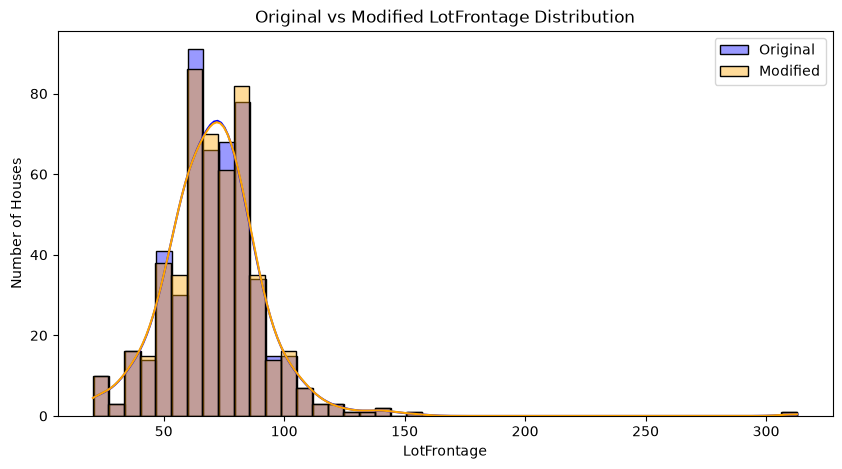

In [63]:
# Original vs Modified Data Distribution

plt.figure(figsize=(10, 5))

sns.histplot(synthetic_data["LotFrontage"],color="blue",label="Original",kde=True,alpha=0.4)

sns.histplot(synthetic_modified["LotFrontage"],color="orange",label="Modified",kde=True,alpha=0.4)

plt.title("Original vs Modified LotFrontage Distribution")
plt.xlabel("LotFrontage")
plt.ylabel("Number of Houses")
plt.legend()
plt.show()

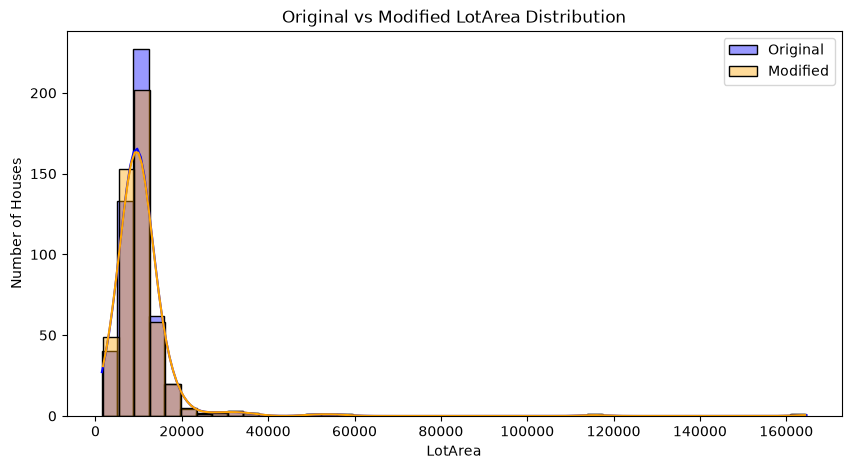

In [64]:
# LotArea Distribution Comparison

plt.figure(figsize=(10, 5))

sns.histplot(synthetic_data["LotArea"],color="blue",label="Original",kde=True,alpha=0.4)

sns.histplot(synthetic_modified["LotArea"],color="orange",label="Modified",kde=True,alpha=0.4)

plt.title("Original vs Modified LotArea Distribution")
plt.xlabel("LotArea")
plt.ylabel("Number of Houses")
plt.legend()
plt.show()

In [65]:
# Correlation Comparison with saleprice

print("Original Correlation:")
print(synthetic_data[["LotFrontage", "LotArea", "SalePrice"]].corr()["SalePrice"])

print("\nModified Correlation:")
print(synthetic_modified[["LotFrontage", "LotArea", "SalePrice"]].corr()["SalePrice"])

Original Correlation:
LotFrontage    0.346098
LotArea        0.240074
SalePrice      1.000000
Name: SalePrice, dtype: float64

Modified Correlation:
LotFrontage    0.345506
LotArea        0.240105
SalePrice      1.000000
Name: SalePrice, dtype: float64


In [66]:
#  Correlation Check between Features

print("Original Feature Correlation:")
display(synthetic_data[["LotFrontage", "LotArea"]].corr())

print("\nModified Feature Correlation:")
display(synthetic_modified[["LotFrontage", "LotArea"]].corr())

Original Feature Correlation:


,LotFrontage,LotArea
LotFrontage,1.000000,0.269581
LotArea,0.269581,1.000000



Modified Feature Correlation:


,LotFrontage,LotArea
LotFrontage,1.000000,0.268733
LotArea,0.268733,1.000000


In [67]:
# check Categorical Features  Category Count 

categorical_cols = synthetic_modified.select_dtypes(include=["object", "str", "string"]).columns.tolist()

print("Total Categorical Features:", len(categorical_cols))

for col in categorical_cols:
    print("\nFeature:", col)
    print("Unique Categories:", synthetic_modified[col].nunique())

Total Categorical Features: 44

Feature: MSSubClass
Unique Categories: 15

Feature: MSZoning
Unique Categories: 5

Feature: Street
Unique Categories: 2

Feature: Alley
Unique Categories: 3

Feature: LotShape
Unique Categories: 3

Feature: LandContour
Unique Categories: 4

Feature: Utilities
Unique Categories: 1

Feature: LotConfig
Unique Categories: 4

Feature: LandSlope
Unique Categories: 3

Feature: Neighborhood
Unique Categories: 24

Feature: Condition1
Unique Categories: 8

Feature: Condition2
Unique Categories: 5

Feature: BldgType
Unique Categories: 5

Feature: HouseStyle
Unique Categories: 8

Feature: RoofStyle
Unique Categories: 5

Feature: RoofMatl
Unique Categories: 5

Feature: Exterior1st
Unique Categories: 12

Feature: Exterior2nd
Unique Categories: 14

Feature: MasVnrType
Unique Categories: 5

Feature: ExterQual
Unique Categories: 4

Feature: ExterCond
Unique Categories: 5

Feature: Foundation
Unique Categories: 6

Feature: BsmtQual
Unique Categories: 5

Feature: BsmtCond


In [68]:
# Category Frequency Check

print("Neighborhood Category Distribution:")

display(synthetic_modified["Neighborhood"].value_counts().to_frame(name="Count"))

Neighborhood Category Distribution:


,Count
Neighborhood,
NAmes,87
OldTown,47
CollgCr,44
NridgHt,33
Edwards,31
Somerst,29
Sawyer,24
NWAmes,24
Gilbert,23


In [69]:
neighborhood_percentage = (synthetic_modified["Neighborhood"].value_counts(normalize=True) * 100).round(2)

display(neighborhood_percentage.to_frame(name="Percentage"))

,Percentage
Neighborhood,
NAmes,17.4
OldTown,9.4
CollgCr,8.8
NridgHt,6.6
Edwards,6.2
Somerst,5.8
Sawyer,4.8
NWAmes,4.8
Gilbert,4.6


In [70]:
original_percentage = (train_data["Neighborhood"].value_counts(normalize=True) * 100)

synthetic_percentage = (synthetic_modified["Neighborhood"].value_counts(normalize=True) * 100)

neighborhood_comparison = pd.DataFrame({"Original Training %": original_percentage,"Synthetic Modified %": synthetic_percentage}).fillna(0)

neighborhood_comparison["Difference"] = (neighborhood_comparison["Synthetic Modified %"]- neighborhood_comparison["Original Training %"])

display(neighborhood_comparison.sort_values(by="Original Training %",ascending=False).round(2))

,Original Training %,Synthetic Modified %,Difference
Neighborhood,,,
NAmes,15.50,17.4,1.90
CollgCr,9.85,8.8,-1.05
OldTown,7.79,9.4,1.61
Edwards,7.45,6.2,-1.25
Somerst,5.91,5.8,-0.11
NWAmes,5.65,4.8,-0.85
Gilbert,5.57,4.6,-0.97
NridgHt,5.22,6.6,1.38
Sawyer,4.97,4.8,-0.17


In [71]:
# Distribution Difference ka Overall Measurement

mean_difference = (neighborhood_comparison["Difference"].abs().mean())

max_difference = (neighborhood_comparison["Difference"].abs().max())

print("Mean Absolute Percentage Difference:", round(mean_difference, 2))
print("Maximum Percentage Difference:", round(max_difference, 2))

Mean Absolute Percentage Difference: 0.66
Maximum Percentage Difference: 1.9


In [72]:
# HouseStyle Distribution

house_style_comparison = pd.DataFrame({
    "Original Training": train_data["HouseStyle"].value_counts(),
    "Synthetic Modified": synthetic_modified["HouseStyle"].value_counts()
}).fillna(0)

display(house_style_comparison)

,Original Training,Synthetic Modified
HouseStyle,,
1.5Fin,121,67
1.5Unf,12,4
1Story,577,247
2.5Fin,7,8
2.5Unf,11,9
2Story,360,127
SFoyer,28,16
SLvl,52,22


In [73]:
# HouseStyle Percentage Comparison

house_style_percentage = pd.DataFrame({
    "Original Training %": (
        train_data["HouseStyle"].value_counts(normalize=True) * 100
    ),
    "Synthetic Modified %": (
        synthetic_modified["HouseStyle"].value_counts(normalize=True) * 100
    )
}).fillna(0)

house_style_percentage["Difference"] = (
    house_style_percentage["Synthetic Modified %"]
    - house_style_percentage["Original Training %"]
)

display(house_style_percentage.round(2))

,Original Training %,Synthetic Modified %,Difference
HouseStyle,,,
1.5Fin,10.36,13.4,3.04
1.5Unf,1.03,0.8,-0.23
1Story,49.40,49.4,-0.00
2.5Fin,0.60,1.6,1.00
2.5Unf,0.94,1.8,0.86
2Story,30.82,25.4,-5.42
SFoyer,2.40,3.2,0.80
SLvl,4.45,4.4,-0.05


In [74]:
house_style_mean_difference = (house_style_percentage["Difference"].abs().mean())

house_style_max_difference = (house_style_percentage["Difference"].abs().max())

print("Mean Absolute Percentage Difference:",round(house_style_mean_difference, 2))

print("Maximum Percentage Difference:",round(house_style_max_difference, 2))

Mean Absolute Percentage Difference: 1.43
Maximum Percentage Difference: 5.42


In [76]:
# KitchenQual Distribution

kitchen_comparison = pd.DataFrame({
    "Original Training": train_data["KitchenQual"].value_counts(),
    "Synthetic Modified": synthetic_modified["KitchenQual"].value_counts()
}).fillna(0)

display(kitchen_comparison)

,Original Training,Synthetic Modified
KitchenQual,,
TA,589,245
Gd,470,214
Ex,77,32
Fa,32,9


In [77]:
kitchen_original_percentage = (train_data["KitchenQual"].value_counts(normalize=True) * 100)

kitchen_synthetic_percentage = (synthetic_modified["KitchenQual"].value_counts(normalize=True) * 100)

kitchen_comparison = pd.DataFrame({"Original Training %": kitchen_original_percentage,"Synthetic Modified %": kitchen_synthetic_percentage
}).fillna(0)

kitchen_comparison["Difference"] = (kitchen_comparison["Synthetic Modified %"] - kitchen_comparison["Original Training %"])

display(kitchen_comparison.round(2))

,Original Training %,Synthetic Modified %,Difference
KitchenQual,,,
TA,50.43,49.0,-1.43
Gd,40.24,42.8,2.56
Ex,6.59,6.4,-0.19
Fa,2.74,1.8,-0.94


In [79]:
# check the current list of Numerical features

modified_features = ["LotFrontage", "LotArea"]

remaining_features = [
    col for col in continuous_cols
    if col not in modified_features
]

print("Remaining Continuous Features:", len(remaining_features))
print(remaining_features)

Remaining Continuous Features: 17
['MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal']


In [80]:
basement_features = ["BsmtFinSF1","BsmtFinSF2","BsmtUnfSF","TotalBsmtSF"]

basement_zero_analysis = (synthetic_modified[basement_features] == 0).sum()

display(basement_zero_analysis.to_frame(name="Zero Count"))

,Zero Count
BsmtFinSF1,169
BsmtFinSF2,446
BsmtUnfSF,34
TotalBsmtSF,11


In [81]:
no_basement_check = synthetic_modified[synthetic_modified["TotalBsmtSF"] == 0][basement_features]

display(no_basement_check)

print("Rows with all basement features zero:",(
        (no_basement_check["BsmtFinSF1"] == 0) &
        (no_basement_check["BsmtFinSF2"] == 0) &
        (no_basement_check["BsmtUnfSF"] == 0)
    ).sum()
)

,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF
646,0,0,0,0
182,0,0,0,0
749,0,0,0,0
39,0,0,0,0
520,0,0,0,0
39,0,0,0,0
1090,0,0,0,0
17,0,0,0,0
17,0,0,0,0
646,0,0,0,0


Rows with all basement features zero: 11


In [82]:
basement_nonzero = synthetic_modified[
    synthetic_modified["TotalBsmtSF"] > 0
][basement_features]

display(basement_nonzero.head(10))

,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF
1267,0,0,2002,2002
992,536,117,169,822
957,417,0,640,1057
401,24,0,1286,1310
725,375,239,250,864
199,1088,0,625,1713
1270,1258,0,74,1332
622,560,0,420,980
100,1200,0,410,1610
1069,220,0,625,845


In [83]:
# Basement Variation Strategy

basement_original = synthetic_modified[basement_features].copy()

print("Backup Shape:", basement_original.shape)

Backup Shape: (500, 4)


In [85]:
# Apply Variation to Basement Features

noise = np.random.normal(
    loc=0,
    scale=synthetic_modified["BsmtFinSF1"].std() * 0.01,
    size=len(synthetic_modified)
)

mask = synthetic_modified["BsmtFinSF1"] > 0

synthetic_modified.loc[mask, "BsmtFinSF1"] = (
    synthetic_modified.loc[mask, "BsmtFinSF1"] + noise[mask]
).clip(lower=0).round(0).astype(int)

In [86]:
print("Original Zero Count:", (basement_original["BsmtFinSF1"] == 0).sum())
print("Modified Zero Count:", (synthetic_modified["BsmtFinSF1"] == 0).sum())
print("Modified Minimum:", synthetic_modified["BsmtFinSF1"].min())

Original Zero Count: 169
Modified Zero Count: 169
Modified Minimum: 0


In [87]:
# BsmtFinSF2 Variation

noise = np.random.normal(
    loc=0,
    scale=synthetic_modified["BsmtFinSF2"].std() * 0.01,
    size=len(synthetic_modified)
)

mask = synthetic_modified["BsmtFinSF2"] > 0

synthetic_modified.loc[mask, "BsmtFinSF2"] = (
    synthetic_modified.loc[mask, "BsmtFinSF2"] + noise[mask]
).clip(lower=0).round(0).astype(int)

In [88]:
print("Original Zero Count:", (basement_original["BsmtFinSF2"] == 0).sum())
print("Modified Zero Count:", (synthetic_modified["BsmtFinSF2"] == 0).sum())
print("Modified Minimum:", synthetic_modified["BsmtFinSF2"].min())

Original Zero Count: 446
Modified Zero Count: 446
Modified Minimum: 0


In [89]:
# BsmtUnfSF Variation

noise = np.random.normal(
    loc=0,
    scale=synthetic_modified["BsmtUnfSF"].std() * 0.01,
    size=len(synthetic_modified)
)

mask = synthetic_modified["BsmtUnfSF"] > 0

synthetic_modified.loc[mask, "BsmtUnfSF"] = (
    synthetic_modified.loc[mask, "BsmtUnfSF"] + noise[mask]
).clip(lower=0).round(0).astype(int)

In [90]:
print("Original Zero Count:", (basement_original["BsmtUnfSF"] == 0).sum())
print("Modified Zero Count:", (synthetic_modified["BsmtUnfSF"] == 0).sum())
print("Modified Minimum:", synthetic_modified["BsmtUnfSF"].min())

Original Zero Count: 34
Modified Zero Count: 34
Modified Minimum: 0


In [91]:
# Recalculate TotalBsmtSF

synthetic_modified["TotalBsmtSF"] = (
    synthetic_modified["BsmtFinSF1"]
    + synthetic_modified["BsmtFinSF2"]
    + synthetic_modified["BsmtUnfSF"]
)

In [92]:
# : Verify Mathematical Relationship

basement_check = (
    synthetic_modified["BsmtFinSF1"]
    + synthetic_modified["BsmtFinSF2"]
    + synthetic_modified["BsmtUnfSF"]
)

difference = synthetic_modified["TotalBsmtSF"] - basement_check

print("Matching Rows:", (difference == 0).sum())
print("Mismatching Rows:", (difference != 0).sum())

Matching Rows: 500
Mismatching Rows: 0


In [93]:
# Compare Original vs Modified Basement Statistics

basement_comparison = pd.DataFrame({
    "Original Mean": basement_original.mean(),
    "Modified Mean": synthetic_modified[basement_features].mean(),
    "Original Std": basement_original.std(),
    "Modified Std": synthetic_modified[basement_features].std()
})

display(basement_comparison.round(2))

,Original Mean,Modified Mean,Original Std,Modified Std
BsmtFinSF1,441.12,440.84,434.54,434.62
BsmtFinSF2,45.35,45.37,162.01,162.06
BsmtUnfSF,587.57,587.57,454.14,453.84
TotalBsmtSF,1074.04,1073.78,436.84,436.91


In [94]:
# Move to Living Area Features

living_features = ["1stFlrSF","2ndFlrSF","LowQualFinSF","GrLivArea"]

living_original = synthetic_modified[living_features].copy()

print("Backup Shape:", living_original.shape)

Backup Shape: (500, 4)


In [95]:
# Check Zero Values in Living Area

living_zero_analysis = (synthetic_modified[living_features] == 0).sum()

display(living_zero_analysis.to_frame(name="Zero Count"))

,Zero Count
1stFlrSF,0
2ndFlrSF,281
LowQualFinSF,488
GrLivArea,0


In [96]:
# Verify Zero Values and Formula

living_check = (
    synthetic_modified["1stFlrSF"]
    + synthetic_modified["2ndFlrSF"]
    + synthetic_modified["LowQualFinSF"]
)

difference = (
    synthetic_modified["GrLivArea"] - living_check
)

print("Matching Rows:", (difference == 0).sum())
print("Mismatching Rows:", (difference != 0).sum())

Matching Rows: 500
Mismatching Rows: 0


In [97]:
# Apply Variation to 1stFlrSF

noise = np.random.normal(
    loc=0,
    scale=synthetic_modified["1stFlrSF"].std() * 0.01,
    size=len(synthetic_modified)
)

synthetic_modified["1stFlrSF"] = (
    synthetic_modified["1stFlrSF"] + noise
).clip(lower=0).round(0).astype(int)

In [98]:
print("Original Minimum:", living_original["1stFlrSF"].min())
print("Modified Minimum:", synthetic_modified["1stFlrSF"].min())

print("Original Mean:", living_original["1stFlrSF"].mean())
print("Modified Mean:", synthetic_modified["1stFlrSF"].mean())

Original Minimum: 372
Modified Minimum: 373
Original Mean: 1185.028
Modified Mean: 1185.1


In [99]:
# Apply Variation to 2ndFlrSF

noise = np.random.normal(
    loc=0,
    scale=synthetic_modified["2ndFlrSF"].std() * 0.01,
    size=len(synthetic_modified)
)

mask = synthetic_modified["2ndFlrSF"] > 0

synthetic_modified.loc[mask, "2ndFlrSF"] = (
    synthetic_modified.loc[mask, "2ndFlrSF"] + noise[mask]
).clip(lower=0).round(0).astype(int)

In [100]:
print("Original Zero Count:", (living_original["2ndFlrSF"] == 0).sum())
print("Modified Zero Count:", (synthetic_modified["2ndFlrSF"] == 0).sum())
print("Modified Minimum:", synthetic_modified["2ndFlrSF"].min())

Original Zero Count: 281
Modified Zero Count: 281
Modified Minimum: 0


In [101]:
# Apply Variation to LowQualFinSF

noise = np.random.normal(
    loc=0,
    scale=synthetic_modified["LowQualFinSF"].std() * 0.01,
    size=len(synthetic_modified)
)

mask = synthetic_modified["LowQualFinSF"] > 0

synthetic_modified.loc[mask, "LowQualFinSF"] = (
    synthetic_modified.loc[mask, "LowQualFinSF"] + noise[mask]
).clip(lower=0).round(0).astype(int)

In [102]:
print("Original Zero Count:", (living_original["LowQualFinSF"] == 0).sum())
print("Modified Zero Count:", (synthetic_modified["LowQualFinSF"] == 0).sum())
print("Modified Minimum:", synthetic_modified["LowQualFinSF"].min())

Original Zero Count: 488
Modified Zero Count: 488
Modified Minimum: 0


In [103]:
# Recalculate GrLivArea

synthetic_modified["GrLivArea"] = (
    synthetic_modified["1stFlrSF"]
    + synthetic_modified["2ndFlrSF"]
    + synthetic_modified["LowQualFinSF"]
)

In [104]:
living_check = (
    synthetic_modified["1stFlrSF"]
    + synthetic_modified["2ndFlrSF"]
    + synthetic_modified["LowQualFinSF"]
)

difference = synthetic_modified["GrLivArea"] - living_check

print("Matching Rows:", (difference == 0).sum())
print("Mismatching Rows:", (difference != 0).sum())

Matching Rows: 500
Mismatching Rows: 0


In [105]:
# Compare Original vs Modified Living Area Statistics

living_comparison = pd.DataFrame({
    "Original Mean": living_original.mean(),
    "Modified Mean": synthetic_modified[living_features].mean(),
    "Original Std": living_original.std(),
    "Modified Std": synthetic_modified[living_features].std()
})

display(living_comparison.round(2))

,Original Mean,Modified Mean,Original Std,Modified Std
1stFlrSF,1185.03,1185.10,391.69,391.61
2ndFlrSF,342.81,342.69,432.14,431.97
LowQualFinSF,6.65,6.64,48.86,48.83
GrLivArea,1534.48,1534.43,494.36,494.28


In [106]:
# Move to Other Areas

other_features = ["GarageArea","WoodDeckSF","OpenPorchSF","EnclosedPorch","3SsnPorch","ScreenPorch","PoolArea","MiscVal"]

In [107]:
other_original = synthetic_modified[other_features].copy()

print("Backup Shape:", other_original.shape)

Backup Shape: (500, 8)


In [108]:
# Check Zero Values in Other Features

other_zero_analysis = (synthetic_modified[other_features] == 0).sum()

display(other_zero_analysis.to_frame(name="Zero Count"))

,Zero Count
GarageArea,26
WoodDeckSF,249
OpenPorchSF,221
EnclosedPorch,434
3SsnPorch,491
ScreenPorch,457
PoolArea,499
MiscVal,480


In [109]:
# Apply Variation to GarageArea

noise = np.random.normal(
    loc=0,
    scale=synthetic_modified["GarageArea"].std() * 0.01,
    size=len(synthetic_modified)
)

mask = synthetic_modified["GarageArea"] > 0

synthetic_modified.loc[mask, "GarageArea"] = (
    synthetic_modified.loc[mask, "GarageArea"] + noise[mask]
).clip(lower=0).round(0).astype(int)

In [110]:
print("Original Zero Count:", (other_original["GarageArea"] == 0).sum())
print("Modified Zero Count:", (synthetic_modified["GarageArea"] == 0).sum())
print("Modified Minimum:", synthetic_modified["GarageArea"].min())

print(
    "GarageCars = 0 but GarageArea > 0:",
    (
        (synthetic_modified["GarageCars"] == 0) &
        (synthetic_modified["GarageArea"] > 0)
    ).sum()
)

Original Zero Count: 26
Modified Zero Count: 26
Modified Minimum: 0
GarageCars = 0 but GarageArea > 0: 0


In [111]:
# Apply Variation to WoodDeckSF

noise = np.random.normal(
    loc=0,
    scale=synthetic_modified["WoodDeckSF"].std() * 0.01,
    size=len(synthetic_modified)
)

mask = synthetic_modified["WoodDeckSF"] > 0

synthetic_modified.loc[mask, "WoodDeckSF"] = (
    synthetic_modified.loc[mask, "WoodDeckSF"] + noise[mask]
).clip(lower=0).round(0).astype(int)

In [112]:
print("Original Zero Count:", (other_original["WoodDeckSF"] == 0).sum())
print("Modified Zero Count:", (synthetic_modified["WoodDeckSF"] == 0).sum())
print("Modified Minimum:", synthetic_modified["WoodDeckSF"].min())

Original Zero Count: 249
Modified Zero Count: 249
Modified Minimum: 0


In [113]:
# Apply Variation to OpenPorchSF

noise = np.random.normal(
    loc=0,
    scale=synthetic_modified["OpenPorchSF"].std() * 0.01,
    size=len(synthetic_modified)
)

mask = synthetic_modified["OpenPorchSF"] > 0

synthetic_modified.loc[mask, "OpenPorchSF"] = (
    synthetic_modified.loc[mask, "OpenPorchSF"] + noise[mask]
).clip(lower=0).round(0).astype(int)

In [114]:
print("Original Zero Count:", (other_original["OpenPorchSF"] == 0).sum())
print("Modified Zero Count:", (synthetic_modified["OpenPorchSF"] == 0).sum())
print("Modified Minimum:", synthetic_modified["OpenPorchSF"].min())

Original Zero Count: 221
Modified Zero Count: 221
Modified Minimum: 0


In [115]:
# Apply Variation to EnclosedPorch

noise = np.random.normal(
    loc=0,
    scale=synthetic_modified["EnclosedPorch"].std() * 0.01,
    size=len(synthetic_modified)
)

mask = synthetic_modified["EnclosedPorch"] > 0

synthetic_modified.loc[mask, "EnclosedPorch"] = (
    synthetic_modified.loc[mask, "EnclosedPorch"] + noise[mask]
).clip(lower=0).round(0).astype(int)

In [116]:
print("Original Zero Count:", (other_original["EnclosedPorch"] == 0).sum())
print("Modified Zero Count:", (synthetic_modified["EnclosedPorch"] == 0).sum())
print("Modified Minimum:", synthetic_modified["EnclosedPorch"].min())

Original Zero Count: 434
Modified Zero Count: 434
Modified Minimum: 0


In [117]:
# Apply Variation to 3SsnPorch

noise = np.random.normal(
    loc=0,
    scale=synthetic_modified["3SsnPorch"].std() * 0.01,
    size=len(synthetic_modified)
)

mask = synthetic_modified["3SsnPorch"] > 0

synthetic_modified.loc[mask, "3SsnPorch"] = (
    synthetic_modified.loc[mask, "3SsnPorch"] + noise[mask]
).clip(lower=0).round(0).astype(int)

In [118]:
print("Original Zero Count:", (other_original["3SsnPorch"] == 0).sum())
print("Modified Zero Count:", (synthetic_modified["3SsnPorch"] == 0).sum())
print("Modified Minimum:", synthetic_modified["3SsnPorch"].min())

Original Zero Count: 491
Modified Zero Count: 491
Modified Minimum: 0


In [119]:
# Handle ScreenPorch

noise = np.random.normal(
    loc=0,
    scale=synthetic_modified["ScreenPorch"].std() * 0.01,
    size=len(synthetic_modified)
)

mask = synthetic_modified["ScreenPorch"] > 0

synthetic_modified.loc[mask, "ScreenPorch"] = (
    synthetic_modified.loc[mask, "ScreenPorch"] + noise[mask]
).clip(lower=0).round(0).astype(int)

In [120]:
print("Original Zero Count:", (other_original["ScreenPorch"] == 0).sum())
print("Modified Zero Count:", (synthetic_modified["ScreenPorch"] == 0).sum())
print("Modified Minimum:", synthetic_modified["ScreenPorch"].min())

Original Zero Count: 457
Modified Zero Count: 457
Modified Minimum: 0


In [121]:
# Handle PoolArea

synthetic_modified.loc[synthetic_modified["PoolArea"] > 0,["PoolArea", "SalePrice"]]

,PoolArea,SalePrice
1386,519,250000


In [122]:
# Handle MiscVal

noise = np.random.normal(
    loc=0,
    scale=synthetic_modified["MiscVal"].std() * 0.01,
    size=len(synthetic_modified)
)

mask = synthetic_modified["MiscVal"] > 0

synthetic_modified.loc[mask, "MiscVal"] = (
    synthetic_modified.loc[mask, "MiscVal"] + noise[mask]
).clip(lower=0).round(0).astype(int)

In [123]:
print("Original Zero Count:", (other_original["MiscVal"] == 0).sum())
print("Modified Zero Count:", (synthetic_modified["MiscVal"] == 0).sum())
print("Modified Minimum:", synthetic_modified["MiscVal"].min())

Original Zero Count: 480
Modified Zero Count: 480
Modified Minimum: 0


In [124]:
print("Negative Values in Other Areas:")

for col in other_features:
    print(col, (synthetic_modified[col] < 0).sum())

Negative Values in Other Areas:
GarageArea 0
WoodDeckSF 0
OpenPorchSF 0
EnclosedPorch 0
3SsnPorch 0
ScreenPorch 0
PoolArea 0
MiscVal 0


In [125]:
# Handle MasVnrArea

print("MasVnrArea Zero Count:",
      (synthetic_modified["MasVnrArea"] == 0).sum())

print("\nMasVnrType Distribution:")
print(synthetic_modified["MasVnrType"].value_counts())

print("\nNone Type but Non-zero Area:")
print(
    ((synthetic_modified["MasVnrType"] == "None") &
     (synthetic_modified["MasVnrArea"] > 0)).sum()
)

MasVnrArea Zero Count: 293

MasVnrType Distribution:
MasVnrType
None       292
BrkFace    155
Stone       46
BrkCmn       5
Unknown      2
Name: count, dtype: int64

None Type but Non-zero Area:
0


In [126]:
# MasVnrArea Analysis

masvnr_original = synthetic_modified["MasVnrArea"].copy()

In [127]:
noise = np.random.normal(
    loc=0,
    scale=synthetic_modified["MasVnrArea"].std() * 0.01,
    size=len(synthetic_modified)
)

mask = synthetic_modified["MasVnrArea"] > 0

synthetic_modified.loc[mask, "MasVnrArea"] = (
    synthetic_modified.loc[mask, "MasVnrArea"] + noise[mask]
).clip(lower=0).round(0).astype(int)

In [128]:
print("Original Zero Count:", (masvnr_original == 0).sum())

print("Modified Zero Count:",
      (synthetic_modified["MasVnrArea"] == 0).sum())

print("Modified Minimum:",
      synthetic_modified["MasVnrArea"].min())

print("None Type but Non-zero Area:",
      ((synthetic_modified["MasVnrType"] == "None") &
       (synthetic_modified["MasVnrArea"] > 0)).sum())

Original Zero Count: 293
Modified Zero Count: 293
Modified Minimum: 0.0
None Type but Non-zero Area: 0


In [129]:
continuous_original = synthetic_data[continuous_cols].describe().T

continuous_modified = synthetic_modified[continuous_cols].describe().T

comparison = pd.DataFrame({
    "Original Mean": continuous_original["mean"],
    "Modified Mean": continuous_modified["mean"],
    "Original Std": continuous_original["std"],
    "Modified Std": continuous_modified["std"]
})

print(comparison.round(2))

               Original Mean  Modified Mean  Original Std  Modified Std
LotFrontage            70.91          70.92         21.99         22.00
LotArea             10904.48       10899.88      10004.98      10014.32
MasVnrArea             96.11          96.10        157.27        157.25
BsmtFinSF1            441.12         440.84        434.54        434.62
BsmtFinSF2             45.35          45.37        162.01        162.06
BsmtUnfSF             587.57         587.57        454.14        453.84
TotalBsmtSF          1074.04        1073.78        436.84        436.91
1stFlrSF             1185.03        1185.10        391.69        391.61
2ndFlrSF              342.81         342.69        432.14        431.97
LowQualFinSF            6.65           6.64         48.86         48.83
GrLivArea            1534.48        1534.43        494.36        494.28
GarageArea            473.32         473.19        216.17        216.05
WoodDeckSF            102.42         102.39        130.39       

In [130]:
# Check Data Shape and Missing Values

print("Original Shape:", synthetic_data.shape)
print("Modified Shape:", synthetic_modified.shape)

print("\nOriginal Missing Values:", synthetic_data.isnull().sum().sum())
print("Modified Missing Values:", synthetic_modified.isnull().sum().sum())

Original Shape: (500, 81)
Modified Shape: (500, 81)

Original Missing Values: 0
Modified Missing Values: 0


In [131]:
# Verify Mathematical Relationships

basement_check = (
    synthetic_modified["BsmtFinSF1"]
    + synthetic_modified["BsmtFinSF2"]
    + synthetic_modified["BsmtUnfSF"]
    == synthetic_modified["TotalBsmtSF"]
)

living_check = (
    synthetic_modified["1stFlrSF"]
    + synthetic_modified["2ndFlrSF"]
    + synthetic_modified["LowQualFinSF"]
    == synthetic_modified["GrLivArea"]
)

print("Basement Matching:", basement_check.sum())
print("Basement Mismatching:", (~basement_check).sum())

print("\nLiving Area Matching:", living_check.sum())
print("Living Area Mismatching:", (~living_check).sum())

Basement Matching: 500
Basement Mismatching: 0

Living Area Matching: 500
Living Area Mismatching: 0


In [132]:
# Verify Garage Relationship

print(
    "GarageCars = 0 but GarageArea > 0:",
    (
        (synthetic_modified["GarageCars"] == 0) &
        (synthetic_modified["GarageArea"] > 0)
    ).sum()
)

print(
    "GarageCars > 0 but GarageArea = 0:",
    (
        (synthetic_modified["GarageCars"] > 0) &
        (synthetic_modified["GarageArea"] == 0)
    ).sum()
)

GarageCars = 0 but GarageArea > 0: 0
GarageCars > 0 but GarageArea = 0: 0


In [133]:
# Verify Categorical Features

categorical_changes = []

for col in categorical_cols:
    if not synthetic_data[col].equals(synthetic_modified[col]):
        categorical_changes.append(col)

print("Categorical Columns Changed:", len(categorical_changes))
print("Changed Columns:", categorical_changes)

Categorical Columns Changed: 0
Changed Columns: []


In [134]:
# Verify SalePrice

print(
    "SalePrice Matching:",
    (synthetic_data["SalePrice"] == synthetic_modified["SalePrice"]).sum()
)

print(
    "SalePrice Mismatching:",
    (synthetic_data["SalePrice"] != synthetic_modified["SalePrice"]).sum()
)

SalePrice Matching: 500
SalePrice Mismatching: 0


In [135]:
# Handle Id Column

print("Total Records:", len(synthetic_modified))

print("Unique IDs:",
      synthetic_modified["Id"].nunique())

print("Duplicate IDs:",
      synthetic_modified["Id"].duplicated().sum())

Total Records: 500
Unique IDs: 407
Duplicate IDs: 93


In [139]:
# Check Discrete, Ordinal and Year Features

year_month_cols = [
    "YearBuilt",
    "YearRemodAdd",
    "GarageYrBlt",
    "MoSold",
    "YrSold"
]

In [140]:
remaining_features = discrete_cols + year_month_cols

remaining_changes = []

for col in remaining_features:
    if not synthetic_data[col].equals(synthetic_modified[col]):
        remaining_changes.append(col)

print("Remaining Features Changed:", len(remaining_changes))
print("Changed Features:", remaining_changes)

Remaining Features Changed: 0
Changed Features: []


In [141]:
# : Final Data Quality Check

print("Total Negative Values:")

print(
    (synthetic_modified[numerical_cols] < 0).sum().sum()
)

Total Negative Values:
0


In [142]:
# Final Validation — Dataset Comparison

total_changes = (
    synthetic_data != synthetic_modified
).sum().sum()

print("Total Changed Values:", total_changes)

Total Changed Values: 4220


In [143]:
synthetic_modified.to_csv("manual_synthetic_data.csv",index=False)